## Import Libraries

In [54]:
import re
import torch
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torch.optim import AdamW
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from transformers import BertTokenizer, BertForSequenceClassification
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

In [55]:
from pathlib import Path

In [56]:
# Prefer the supplied CSV; use the Excel copy only when no CSV is available.
data_candidates = [
    Path("Resume.csv"),
    Path("Resume.xlsx"),
    Path("Dataset") / "Resume.csv",
    Path("Dataset") / "Resume.xlsx",
]
resume_data_path = next((path for path in data_candidates if path.is_file()), None)
if resume_data_path is None:
    searched_paths = ", ".join(str(path) for path in data_candidates)
    raise FileNotFoundError(f"Could not find Resume.csv or Resume.xlsx. Searched: {searched_paths}")

if resume_data_path.suffix.lower() == ".csv":
    df = pd.read_csv(resume_data_path)
elif resume_data_path.suffix.lower() in {".xlsx", ".xls"}:
    df = pd.read_excel(resume_data_path)
else:
    raise ValueError(f"Unsupported resume dataset format: {resume_data_path.suffix}")

required_columns = {"Resume_str", "Category"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

print(f"Loaded {len(df):,} rows from {resume_data_path.resolve()}")
df.head(10)

Loaded 2,484 rows from C:\Projects\resume analyzer_\Resume.csv


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR
5,11592605,HR GENERALIST Summary Dedic...,"<div class=""fontsize fontface vmargins hmargin...",HR
6,25824789,HR MANAGER Summary HUMAN RES...,"<div class=""fontsize fontface vmargins hmargin...",HR
7,15375009,HR MANAGER Professional Summa...,"<div class=""fontsize fontface vmargins hmargin...",HR
8,11847784,HR SPECIALIST Summary Posses...,"<div class=""fontsize fontface vmargins hmargin...",HR
9,32896934,HR CLERK Summary Translates ...,"<div class=""fontsize fontface vmargins hmargin...",HR


### Statistical anaylsis of the dataset

In [57]:
# resume_csv_path= '/kaggle/input/resume-data/Resume.csv'
# df=pd.read_csv(resume_csv_path)
# df.head(10)

In [58]:
df.describe()

,ID
count,2.484000e+03
mean,3.182616e+07
std,2.145735e+07
min,3.547447e+06
25%,1.754430e+07
50%,2.521031e+07
75%,3.611444e+07
max,9.980612e+07


In [59]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ID           2484 non-null   int64
 1   Resume_str   2484 non-null   str  
 2   Resume_html  2484 non-null   str  
 3   Category     2484 non-null   str  
dtypes: int64(1), str(3)
memory usage: 52.3 MB


### Check missing values

In [60]:
missing_values = df.isnull().sum()
print(missing_values)

ID             0
Resume_str     0
Resume_html    0
Category       0
dtype: int64


### Distribution of Categories

Task was destroyed but it is pending!
task: <Task pending name='Task-537' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-538' coro=<Kernel.shell_main() running at C:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\zmq\eventloop\zmqstream.py:563]>
C:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\matplotlib\cbook.py:2028: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  orig = getattr(obj, attr, sentinel)
Task was destroyed but it is pending!
task: <Task pending name='Task-538' coro=<Kernel.shell_main() running at C:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\ipykernel\kernelbase.

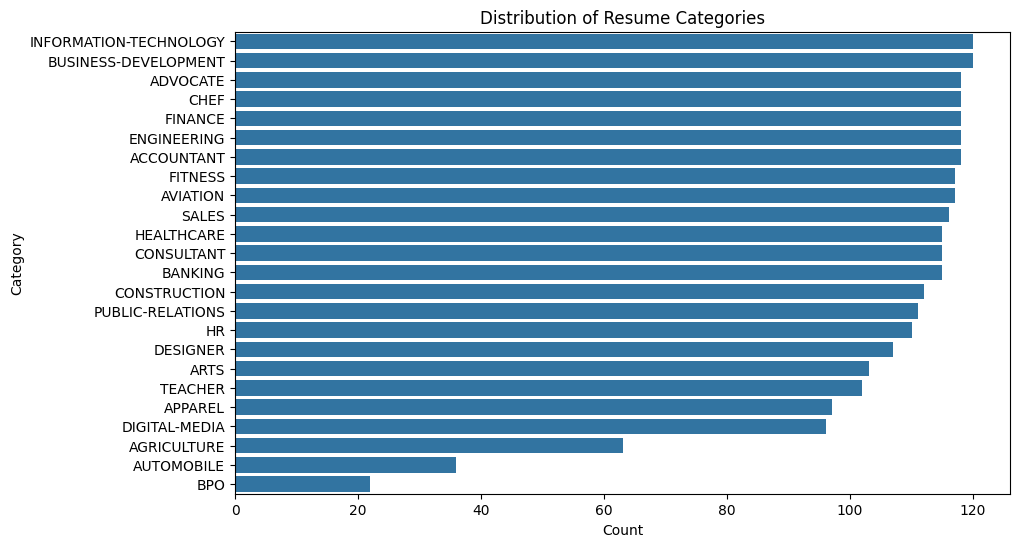

In [61]:
plt.figure(figsize=(10, 6))
sns.countplot(y='Category', data=df, order=df['Category'].value_counts().index)
plt.title('Distribution of Resume Categories')
plt.xlabel('Count')
plt.ylabel('Category')
plt.show()

### Length of Resumes

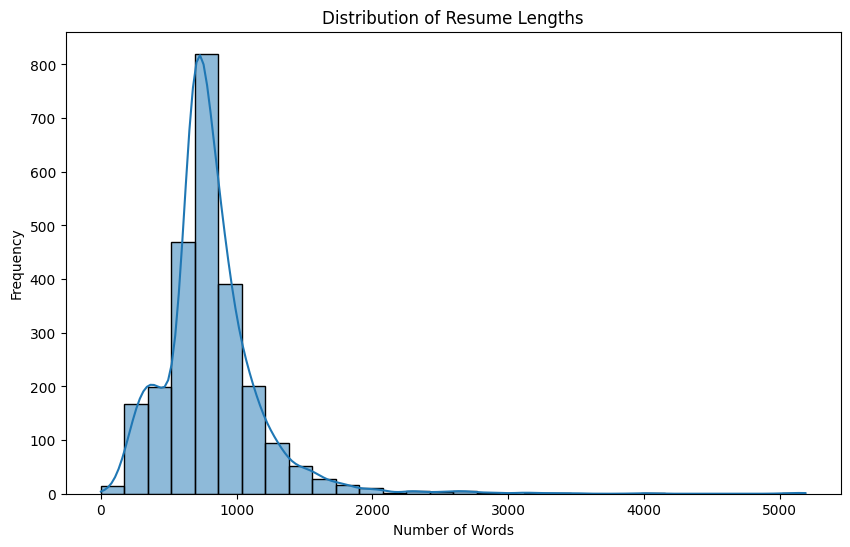

In [62]:
df['resume_length'] = df['Resume_str'].apply(lambda x: len(x.split()))
plt.figure(figsize=(10, 6))
sns.histplot(df['resume_length'], bins=30, kde=True)
plt.title('Distribution of Resume Lengths')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.show()

## Category vs Resume Length

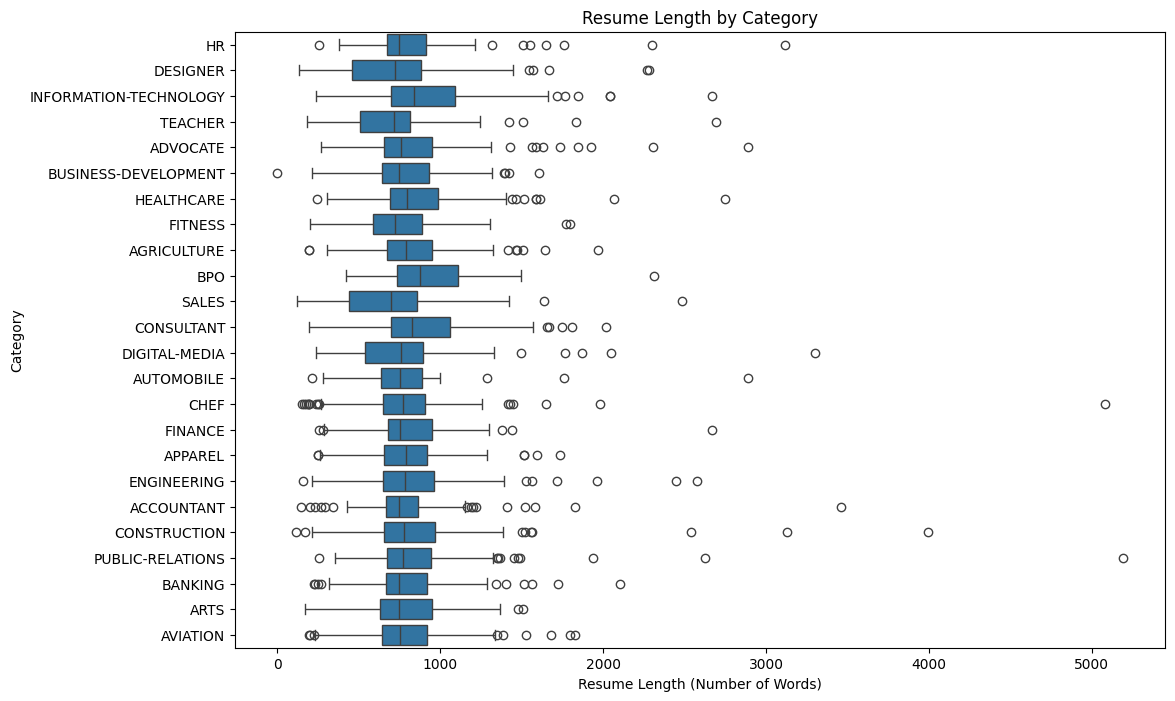

In [63]:
plt.figure(figsize=(12, 8))
sns.boxplot(x='resume_length', y='Category', data=df)
plt.title('Resume Length by Category')
plt.xlabel('Resume Length (Number of Words)')
plt.ylabel('Category')
plt.show()

## Data Processing

### Inspect and Clean Data

In [64]:
def clean_text(text):
    return re.sub(r'<.*?>', '', str(text))

# Keep rows with usable text and labels; unrelated columns such as Resume_html may be empty.
df = df.dropna(subset=["Resume_str", "Category"]).copy()
df["Resume_str"] = df["Resume_str"].apply(clean_text)
df["Category"] = df["Category"].astype(str).str.strip()
df = df[df["Resume_str"].str.strip().ne("") & df["Category"].ne("")].copy()

# Label Encoding the target
label_encoder = LabelEncoder()
df["Category"] = label_encoder.fit_transform(df["Category"])

In [65]:
df.head()

,ID,Resume_str,Resume_html,Category,resume_length
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",19,674
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",19,708
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",19,1017
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",19,379
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",19,1206


### Split the dataset

In [66]:
X_train, X_test, y_train, y_test = train_test_split(
    df['Resume_str'], df['Category'], test_size=0.2, random_state=42, stratify=df['Category']
)
MAX_TRAIN_SAMPLES_PER_CLASS = 50
original_train_size = len(X_train)
train_data = pd.DataFrame({'text': X_train, 'label': y_train})
train_data = pd.concat(
    [
        group.sample(n=min(len(group), MAX_TRAIN_SAMPLES_PER_CLASS), random_state=42)
        for _, group in train_data.groupby('label')
    ]
)
X_train = train_data['text']
y_train = train_data['label']
print(f'Training rows after class-balanced cap: {len(X_train):,} / {original_train_size:,}')
print('X_train shape: ',X_train.shape)
print('y_train shape: ',y_train.shape)
print('X_test shape: ',X_test.shape)
print('y_test shape: ',y_test.shape)

Training rows after class-balanced cap: 1,147 / 1,986
X_train shape:  (1147,)
y_train shape:  (1147,)
X_test shape:  (497,)
y_test shape:  (497,)


In [67]:
print('Sample resume text: \n', X_train.iloc[0])
print('Sample resume label: \n', y_train.iloc[0])

Sample resume text: 
          SENIOR ACCOUNTANT           Summary    Experienced Senior Corporate Accountant dedicated to accounting and financial excellence, seeking to utilize skills and in-depth expertise in Accounting (GAAP), General Ledger Reconciliation, Variance Analysis, Financial Reporting, Team Management and Process Improvement to help achieve your company's goals.      Highlights          Microsoft Excel expert - Pivot Tables, V-Lookups, Formulas   Access Database Queries & data mining  Proficient in Microsoft Office, MS Word, Outlook, PowerPoint   SharePoint  PeopleSoft knowledge - Queries & data mining  Oracle   InfoLease for Lease and Financial Accounting  CITConnect Research  Internet Accounting, Finance and Tax Research - Lexis-Nexis, CCH & RIA Tax Research  STAT- FSI Track  Ultra Tax   IMAGE Scanner - Asset Manager -10-key; Printers & Scanners; general office tools   QuickBooks       Account reconciliation expert  Financial statement analysis  Working Knowledge of GA

### Tokenization and Model Configuration

In [68]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

def tokenize_data(texts):
    return tokenizer(
        texts.tolist(),
        max_length=512,
        padding=True,
        truncation=True,
        return_tensors="pt"
    )

train_encodings = tokenize_data(X_train)
test_encodings = tokenize_data(X_test)


In [69]:
test_encodings.keys()

KeysView({'input_ids': tensor([[  101,  5859, 12654,  ...,     0,     0,     0],
        [  101,  3617,  5821,  ...,  3024,  1037,   102],
        [  101,  6845,  8913,  ..., 14048,  1010,   102],
        ...,
        [  101,  4007,  2490,  ...,  3919,  3036,   102],
        [  101, 17850, 10669,  ...,  1013, 17850,   102],
        [  101,  8013,  2326,  ...,  2041,  1012,   102]]), 'token_type_ids': tensor([[0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        ...,
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 1, 1, 1],
        [1, 1, 1,  ..., 1, 1, 1],
        ...,
        [1, 1, 1,  ..., 1, 1, 1],
        [1, 1, 1,  ..., 1, 1, 1],
        [1, 1, 1,  ..., 1, 1, 1]])})

In [70]:
model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=len(label_encoder.classes_))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [71]:
print("Model architecture: \n",model)

Model architecture: 
 BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNo

## Data Loader for model training

In [72]:
class ResumeDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

train_dataset = ResumeDataset(train_encodings, y_train.values)
test_dataset = ResumeDataset(test_encodings, y_test.values)


In [73]:
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)


### Model training

In [ ]:
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)

optimizer = AdamW(model.parameters(), lr=5e-5)

for epoch in range(2):  # Fine-tune for two epochs on the stratified training subset
    model.train()
    for batch in train_loader:
        # Move batch to the device
        batch = {k: v.to(device) for k, v in batch.items()}

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(**batch)
        loss = outputs.loss
        loss.backward()

        # Optimize
        optimizer.step()

    print(f'Epoch {epoch + 1} completed.')


C:\Users\ASUS\AppData\Local\Temp\ipykernel_2032\3545919771.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}


## Model Evaluation

In [ ]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)
        _, preds = torch.max(outputs.logits, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(batch['labels'].cpu().numpy())

# Calculate accuracy
accuracy = accuracy_score(all_labels, all_preds)
print(f'Test Accuracy: {accuracy * 100:.2f}%')

# Classification report
print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))


In [ ]:
precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted')
print(f'Test Accuracy: {accuracy:.2f}')
print(f'Precision: {precision:.2f}')
print(f'Recall: {recall:.2f}')
print(f'F1 Score: {f1:.2f}')


In [ ]:
def visualize_metrics(accuracy, precision, recall, f1):
    metrics = {'Accuracy': accuracy, 'Precision': precision, 'Recall': recall, 'F1 Score': f1}
    metric_names = list(metrics.keys())
    metric_values = list(metrics.values())

    plt.figure(figsize=(10, 5))
    sns.barplot(x=metric_names, y=metric_values)
    plt.title('Model Performance Metrics')
    plt.ylim(0, 1)
    plt.ylabel('Score')
    plt.show()

visualize_metrics(accuracy,precision,recall,f1)

## Save the model

In [ ]:
model.save_pretrained('models/resume_classification_model')
tokenizer.save_pretrained('models/resume_classification_model')